# ASE'22 Tseitin Evaluation

This notebook adapts the original `ase22_evaluation.R` analysis to torte stage outputs. It summarizes transformation/runtime behavior and model-count preservation relative to the Z3 Tseitin baseline.

In [ ]:
from decimal import Decimal, InvalidOperation, getcontext
from pathlib import Path, PurePosixPath
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

evaluation_main = Path(os.getenv("DOCKER_SRC_DIRECTORY", "../../src")) / "evaluation" / "main.py"
exec(open(evaluation_main).read(), globals())

getcontext().prec = 80
BASELINE = "Z3"

TRANSFORM_CSV = Path(get_stage_directory("transform_to_dimacs", key="transform")) / "output.csv"
SAT_CSV = Path(get_stage_directory("solve_sat", key="sat")) / "output.csv"
SHARP_CSV = Path(get_stage_directory("solve_sharp_sat", key="sharp")) / "output.csv"
print("transform:", TRANSFORM_CSV)
print("sat:", SAT_CSV)
print("sharp:", SHARP_CSV)


transform: ../../stages-tseitin2/17_transform_to_dimacs/output.csv
sat: ../../stages-tseitin2/77_solve_sat/output.csv
sharp: ../../stages-tseitin2/90_solve_sharp_sat/output.csv


In [2]:
TRANSFORM_LABELS = {
    "transform-to-dimacs-with-featureide": "FeatureIDE",
    "transform-to-dimacs-with-kconfigreader": "KConfigReader",
    "transform-smt-to-dimacs-with-z3": "Z3",
}


def to_number(series):
    return pd.to_numeric(series, errors="coerce")


def normalize_transformer(value):
    text = str(value)
    return TRANSFORM_LABELS.get(text, text)


def dimacs_parts(dimacs_file):
    parts = PurePosixPath(str(dimacs_file)).parts
    transformer = parts[0] if parts and parts[0].startswith("transform") else ""
    rest = "/".join(parts[1:] if transformer else parts)
    return pd.Series({
        "dimacs_transformer_from_file": normalize_transformer(transformer),
        "model_key": re.sub(r"\.dimacs$", "", rest),
    })


def solver_short(value):
    text = str(value)
    text = text.split("/")[-1]
    text = text.removesuffix(".sh")
    return text


def query_to_analysis(query, is_sharp):
    query = str(query)
    head = query.split()[0] if query else ""
    if is_sharp:
        return "FMC" if head == "void" else "FC"
    if head in {"core", "dead"}:
        return "Core/Dead"
    return "Void"


def parse_count(value):
    text = str(value).strip()
    if not re.fullmatch(r"[0-9]+", text):
        return pd.NA
    return text


def decimal_ratio(value, baseline):
    try:
        if pd.isna(value) or pd.isna(baseline):
            return np.nan
        den = Decimal(str(baseline))
        if den == 0:
            return np.nan
        return float(Decimal(str(value)) / den)
    except (InvalidOperation, ValueError):
        return np.nan


In [3]:
transform = pd.read_csv(TRANSFORM_CSV, dtype=str)
transform = transform.join(transform["dimacs_file"].apply(dimacs_parts))
# Failed transformations use <transformer>/NA; retain their input model keys.
failed_transform = transform["model_key"].eq("NA") | transform["dimacs_file"].isna()
transform.loc[failed_transform, "model_key"] = (
    transform.loc[failed_transform, "model_file"].str.replace(r"\.model$", "", regex=True)
)
transform["transformation"] = transform["dimacs_transformer"].apply(normalize_transformer)
transform["transform_time"] = to_number(transform.get("dimacs_time"))
transform["transform_variables"] = to_number(transform.get("dimacs_variables"))
transform["transform_literals"] = to_number(transform.get("dimacs_literals"))
# torte records elapsed time even for unsuccessful transformations.
transform["transform_time"] = transform["transform_time"].where(
    transform["transform_variables"].notna() & transform["transform_literals"].notna()
)

transform_summary = (
    transform.groupby(["model_key", "transformation"], dropna=False)
    .agg(
        transform_time=("transform_time", "median"),
        transform_variables=("transform_variables", "median"),
        transform_literals=("transform_literals", "median"),
    )
    .reset_index()
)

baseline_transform = transform_summary[transform_summary["transformation"].eq(BASELINE)][["model_key", "transform_time"]]
baseline_transform = baseline_transform.rename(columns={"transform_time": "baseline_transform_time"})
transform_summary = transform_summary.merge(baseline_transform, on="model_key", how="left")
transform_summary["time_rel"] = transform_summary["transform_time"] / transform_summary["baseline_transform_time"]
transform_summary["analysis"] = "Transformation"

display(transform_summary.head())
print(f"Loaded {len(transform):,} transformation rows for {transform_summary['model_key'].nunique():,} model keys.")


,model_key,transformation,transform_time,transform_variables,transform_literals,baseline_transform_time,time_rel,analysis
0,extract-kconfig-models-with-kclause/1/axtls/re...,FeatureIDE,3.735327e+08,124.0,804.0,61636245.0,6.060277,Transformation
1,extract-kconfig-models-with-kclause/1/axtls/re...,KConfigReader,4.629564e+08,125.0,848.0,61636245.0,7.511106,Transformation
2,extract-kconfig-models-with-kclause/1/axtls/re...,Z3,6.163624e+07,176.0,1046.0,61636245.0,1.000000,Transformation
3,extract-kconfig-models-with-kclause/1/buildroo...,FeatureIDE,NaN,NaN,NaN,305972138.0,NaN,Transformation
4,extract-kconfig-models-with-kclause/1/buildroo...,KConfigReader,4.219305e+09,19178.0,320554.0,305972138.0,13.789835,Transformation


Loaded 168 transformation rows for 62 model keys.


In [4]:
sat = pd.read_csv(SAT_CSV, dtype=str)
sharp = pd.read_csv(SHARP_CSV, dtype=str)

sat = sat.join(sat["dimacs_file"].apply(dimacs_parts))
sharp = sharp.join(sharp["dimacs_file"].apply(dimacs_parts))

sat["transformation"] = sat["dimacs_transformer_from_file"]
sharp["transformation"] = sharp["dimacs_transformer_from_file"]
sat["solver"] = sat["dimacs_solver"].apply(solver_short)
sharp["solver"] = sharp["dimacs_solver"].apply(solver_short)
sat["analysis"] = sat["dimacs_query"].apply(lambda q: query_to_analysis(q, False))
sharp["analysis"] = sharp["dimacs_query"].apply(lambda q: query_to_analysis(q, True))
sat["solve_time"] = to_number(sat["dimacs_solver_time"])
sharp["solve_time"] = to_number(sharp["dimacs_solver_time"])
sharp["model_count"] = sharp["sharp_sat"].apply(parse_count)
# A timeout/failure still has an elapsed time, but no usable solver result.
sat["solve_time"] = sat["solve_time"].where(sat["sat"].isin(["true", "false"]))
sharp["solve_time"] = sharp["solve_time"].where(sharp["model_count"].notna())

solve = pd.concat([
    sat[["model_key", "transformation", "solver", "analysis", "dimacs_query", "solve_time"]],
    sharp[["model_key", "transformation", "solver", "analysis", "dimacs_query", "solve_time", "model_count"]],
], ignore_index=True)

solve_summary = (
    solve.groupby(["model_key", "transformation", "solver", "analysis"], dropna=False)
    # Like median(..., na.rm=FALSE) in the R script, retain failed groups.
    .agg(solve_time=("solve_time", lambda values: np.median(values.to_numpy())))
    .reset_index()
)
baseline_solve = solve_summary[solve_summary["transformation"].eq(BASELINE)][["model_key", "solver", "analysis", "solve_time"]]
baseline_solve = baseline_solve.rename(columns={"solve_time": "baseline_solve_time"})
solve_summary = solve_summary.merge(baseline_solve, on=["model_key", "solver", "analysis"], how="left")
solve_summary["time_rel"] = solve_summary["solve_time"] / solve_summary["baseline_solve_time"]

display(solve_summary.head())
print(f"Loaded {len(sat):,} SAT rows and {len(sharp):,} #SAT rows.")


,model_key,transformation,solver,analysis,solve_time,baseline_solve_time,time_rel
0,extract-kconfig-models-with-kclause/1/axtls/re...,FeatureIDE,02-zchaff,Core/Dead,2424693.5,2445700.5,0.991411
1,extract-kconfig-models-with-kclause/1/axtls/re...,FeatureIDE,02-zchaff,Void,2280006.0,2439006.0,0.934810
2,extract-kconfig-models-with-kclause/1/axtls/re...,FeatureIDE,03-Forklift,Core/Dead,6444501.0,6606889.0,0.975421
3,extract-kconfig-models-with-kclause/1/axtls/re...,FeatureIDE,03-Forklift,Void,5923377.0,6465600.0,0.916137
4,extract-kconfig-models-with-kclause/1/axtls/re...,FeatureIDE,04-zchaff,Core/Dead,2380822.0,2478745.0,0.960495


Loaded 18,898 SAT rows and 2,998 #SAT rows.


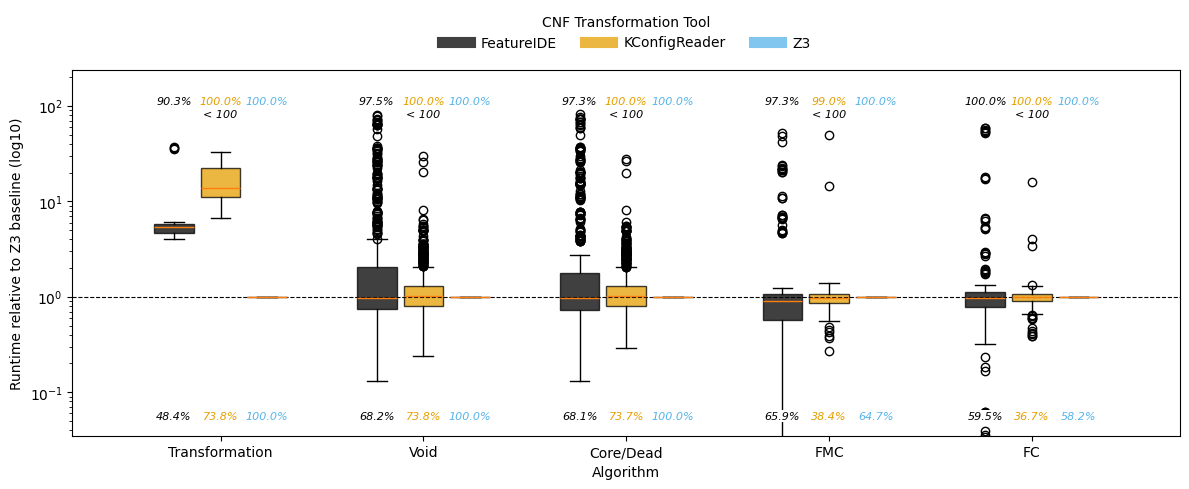

count        mean         std       min  \
analysis       transformation                                            
Core/Dead      FeatureIDE      539.0   19.771967   85.968167  0.132662   
               KConfigReader   809.0    1.346575    1.695595  0.291421   
               Z3              810.0    1.000000    0.000000  1.000000   
FC             FeatureIDE      131.0    4.059369   11.659804  0.033945   
               KConfigReader   112.0    1.141076    1.485686  0.389288   
               Z3              131.0    1.000000    0.000000  1.000000   
FMC            FeatureIDE      145.0    9.466086   28.825398  0.034276   
               KConfigReader   117.0  104.649510  779.956699  0.271014   
               Z3              145.0    1.000000    0.000000  1.000000   
Transformation FeatureIDE       30.0   37.607962   60.838149  4.010239   
               KConfigReader    45.0   15.874568    7.056208  6.666840   
               Z3               45.0    1.000000    0.000000  1.000000   
Void           FeatureIDE      540.0   18.074314   79.815240  0.130348   
               KConfigReader   810.0    1.345249    1.734743  0.238271   
               Z3              810.0    1.000000    0.000000  1.000000   

                                     25%        50%        75%          max  
analysis       transformation                                                
Core/Dead      FeatureIDE       0.741056   0.983627   3.861902   957.476805  
               KConfigReader    0.797083   1.007884   1.299252    27.594977  
               Z3               1.000000   1.000000   1.000000     1.000000  
FC             FeatureIDE       0.790741   0.981838   1.129125    58.931424  
               KConfigReader    0.910817   0.989315   1.075917    16.116332  
               Z3               1.000000   1.000000   1.000000     1.000000  
FMC            FeatureIDE       0.595715   0.916664   1.240654   175.563655  
               KConfigReader    0.869963   0.977438   1.085209  6869.233220  
               Z3               1.000000   1.000000   1.000000     1.000000  
Transformation FeatureIDE       4.796863   5.708959  35.794090   199.739564  
               KConfigReader   11.212554  13.875063  22.180390    32.718341  
               Z3               1.000000   1.000000   1.000000     1.000000  
Void           FeatureIDE       0.744232   0.978143   3.885345   891.078732  
               KConfigReader    0.791573   1.020223   1.303671    30.032843  
               Z3               1.000000   1.000000   1.000000     1.000000

total  completed  within_cutoff  completed_pct  \
analysis       transformation                                                   
Core/Dead      FeatureIDE        792        539            771      68.055556   
               KConfigReader    1098        809           1098      73.679417   
               Z3                810        810            810     100.000000   
FC             FeatureIDE        220        131            220      59.545455   
               KConfigReader     305        112            305      36.721311   
               Z3                225        131            225      58.222222   
FMC            FeatureIDE        220        145            214      65.909091   
               KConfigReader     305        117            302      38.360656   
               Z3                224        145            224      64.732143   
Transformation FeatureIDE         62         30             56      48.387097   
               KConfigReader      61         45             61      73.770492   
               Z3                 45         45             45     100.000000   
Void           FeatureIDE        792        540            772      68.181818   
               KConfigReader    1098        810           1098      73.770492   
               Z3                810        810            810     100.000000   

                               within_cutoff_pct  
analysis       transformation                     
Core/Dead      FeatureIDE              97.348485  
               KConfigReader          100.000000  
               Z3                     100.000000  
FC             FeatureIDE             100.000000  
               KConfigReader          100.000000  
               Z3                     100.000000  
FMC            FeatureIDE              97.272727  
               KConfigReader           99.016393  
               Z3                     100.000000  
Transformation FeatureIDE              90.322581  
               KConfigReader          100.000000  
               Z3                     100.000000  
Void           FeatureIDE              97.474747  
               KConfigReader          100.000000  
               Z3                     100.000000

In [5]:
time_data = pd.concat([
    transform_summary[["transformation", "analysis", "time_rel"]],
    solve_summary[["transformation", "analysis", "time_rel"]],
], ignore_index=True)
# Keep missing ratios in the denominator for the completion annotations.
time_data = time_data.replace([np.inf, -np.inf], np.nan)

# Match ase22_evaluation.R: lower labels show available relative runtimes;
# upper labels show the fraction not exceeding the plot cutoff (including NAs).
time_percentages = (
    time_data.groupby(["analysis", "transformation"])["time_rel"]
    .agg(
        total="size",
        completed=lambda values: values.notna().sum(),
        within_cutoff=lambda values: (~values.gt(1e2)).sum(),
    )
)
time_percentages["completed_pct"] = 100 * time_percentages["completed"] / time_percentages["total"]
time_percentages["within_cutoff_pct"] = 100 * time_percentages["within_cutoff"] / time_percentages["total"]

order = ["Transformation", "Void", "Core/Dead", "FMC", "FC"]
transformations = ["FeatureIDE", "KConfigReader", "Z3"]
fig, ax = plt.subplots(figsize=(12, 5))
positions = []
labels = []
data = []
width = 0.23
for i, analysis in enumerate(order):
    for j, transformation in enumerate(transformations):
        values = time_data[(time_data["analysis"].eq(analysis)) & (time_data["transformation"].eq(transformation))]["time_rel"]
        values = values[(values > 0) & (values < 1e2)]
        if len(values):
            data.append(values.to_numpy())
            positions.append(i + (j - 1) * width)
            labels.append(transformation)
bp = ax.boxplot(data, positions=positions, widths=width * 0.85, patch_artist=True, showfliers=True)
colors = {"FeatureIDE": "#000000", "KConfigReader": "#E69F00", "Z3": "#56B4E9"}
for patch, label in zip(bp["boxes"], labels):
    patch.set_facecolor(colors[label])
    patch.set_alpha(0.75)
for i, analysis in enumerate(order):
    for j, transformation in enumerate(transformations):
        key = (analysis, transformation)
        if key not in time_percentages.index:
            continue
        percentages = time_percentages.loc[key]
        x = i + (j - 1) * width
        for y, column in [(0.05, "completed_pct"), (100, "within_cutoff_pct")]:
            ax.text(x, y, f"{percentages[column]:.1f}%", ha="center", va="bottom",
                    color=colors[transformation], fontsize=8, fontstyle="italic",
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
    ax.text(i, 72, "< 100", ha="center", va="bottom", fontsize=8, fontstyle="italic")
ax.axhline(1, color="black", linestyle="--", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(0.035, 240)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order)
ax.set_xlabel("Algorithm")
ax.set_ylabel("Runtime relative to Z3 baseline (log10)")
handles = [plt.Line2D([0], [0], color=colors[t], lw=8, alpha=0.75) for t in transformations]
ax.legend(handles, transformations, title="CNF Transformation Tool",
          loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

display(time_data.groupby(["analysis", "transformation"])["time_rel"].describe())
display(time_percentages)


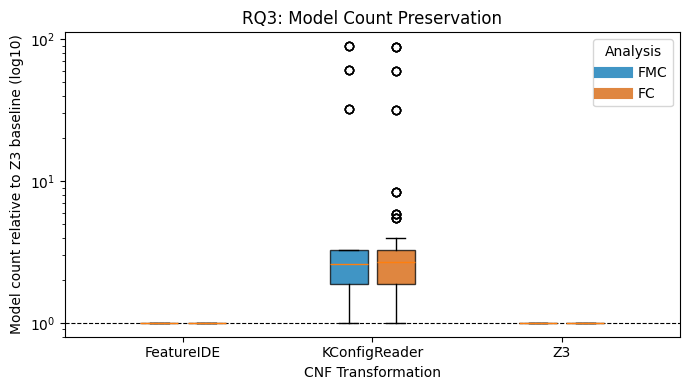

count          mean           std  min       25%  \
analysis transformation                                                     
FC       FeatureIDE      388.0  1.000000e+00  0.000000e+00  1.0  1.000000   
         KConfigReader   339.0  3.421032e+74  2.552379e+75  1.0  1.885009   
         Z3              388.0  1.000000e+00  0.000000e+00  1.0  1.000000   
FMC      FeatureIDE      145.0  1.000000e+00  0.000000e+00  1.0  1.000000   
         KConfigReader   117.0  4.956111e+74  3.068292e+75  1.0  2.142852   
         Z3              145.0  1.000000e+00  0.000000e+00  1.0  1.000000   

                              50%         75%           max  
analysis transformation                                      
FC       FeatureIDE      1.000000    1.000000  1.000000e+00  
         KConfigReader   3.292367  256.000000  1.932883e+76  
         Z3              1.000000    1.000000  1.000000e+00  
FMC      FeatureIDE      1.000000    1.000000  1.000000e+00  
         KConfigReader   3.292367  451.134564  1.932883e+76  
         Z3              1.000000    1.000000  1.000000e+00

In [6]:
count_rows = sharp.dropna(subset=["model_count"]).copy()
count_summary = (
    count_rows.groupby(["model_key", "transformation", "solver", "analysis", "dimacs_query"], dropna=False)
    .agg(model_count=("model_count", lambda s: s.dropna().iloc[len(s.dropna()) // 2] if len(s.dropna()) else pd.NA))
    .reset_index()
)
baseline_counts = count_summary[count_summary["transformation"].eq(BASELINE)][[
    "model_key", "solver", "analysis", "dimacs_query", "model_count"
]].rename(columns={"model_count": "baseline_model_count"})
count_summary = count_summary.merge(baseline_counts, on=["model_key", "solver", "analysis", "dimacs_query"], how="left")
count_summary["model_count_rel"] = [
    decimal_ratio(value, baseline)
    for value, baseline in zip(count_summary["model_count"], count_summary["baseline_model_count"])
]
plot_counts = count_summary.replace([np.inf, -np.inf], np.nan).dropna(subset=["model_count_rel"])
plot_counts = plot_counts[(plot_counts["model_count_rel"] > 0) & (plot_counts["model_count_rel"] < 1e2)]

fig, ax = plt.subplots(figsize=(7, 4))
data = []
positions = []
labels = []
for i, transformation in enumerate(transformations):
    for j, analysis in enumerate(["FMC", "FC"]):
        values = plot_counts[(plot_counts["transformation"].eq(transformation)) & (plot_counts["analysis"].eq(analysis))]["model_count_rel"]
        if len(values):
            data.append(values.to_numpy())
            positions.append(i + (j - 0.5) * 0.25)
            labels.append(analysis)
bp = ax.boxplot(data, positions=positions, widths=0.2, patch_artist=True, showfliers=True)
analysis_colors = {"FMC": "#0072B2", "FC": "#D55E00"}
for patch, label in zip(bp["boxes"], labels):
    patch.set_facecolor(analysis_colors[label])
    patch.set_alpha(0.75)
ax.axhline(1, color="black", linestyle="--", linewidth=0.8)
ax.set_yscale("log")
ax.set_xticks(range(len(transformations)))
ax.set_xticklabels(transformations)
ax.set_xlabel("CNF Transformation")
ax.set_ylabel("Model count relative to Z3 baseline (log10)")
handles = [plt.Line2D([0], [0], color=analysis_colors[a], lw=8, alpha=0.75) for a in ["FMC", "FC"]]
ax.legend(handles, ["FMC", "FC"], title="Analysis")
ax.set_title("RQ3: Model Count Preservation")
fig.tight_layout()
plt.show()

display(count_summary.groupby(["analysis", "transformation"])["model_count_rel"].describe())
